<a href="https://colab.research.google.com/github/vandau16/THXDMHTTNT/blob/main/Bai4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI 4. XÂY DỰNG PIPELINE DỰ ĐOÁN GIÁ NHÀ – `kc_house_data`

## Mục tiêu
- Nạp và khảo sát dữ liệu nhà ở King County; dự đoán `price`.
- Xây dựng **pipeline** tiền xử lý để tránh rò rỉ dữ liệu: điền giá trị thiếu, chuẩn hóa biến số, mã hóa biến phân loại.
- Thử nhiều trường hợp **Feature Engineering**: tách thông tin ngày bán, tuổi nhà, trạng thái cải tạo và các tỷ lệ diện tích.
- Thử **Feature Selection** theo hai cách: `SelectKBest` và `SelectFromModel`.
- So sánh nhiều thuật toán hồi quy bằng **MAE, RMSE, R² và MAPE** trên cùng tập kiểm tra.


## 4.1. Import thư viện và nạp dữ liệu

In [3]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression, SelectFromModel, RFE
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    GradientBoostingRegressor, HistGradientBoostingRegressor
)
from sklearn.svm import LinearSVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# Nguồn dự phòng để notebook vẫn hoạt động nếu một kho GitHub không khả dụng.
DATA_URLS = [
    "https://raw.githubusercontent.com/remijul/dataset/master/kc_house_data.csv",
    "https://raw.githubusercontent.com/viviandng/flatiron-project-2/master/kc_house_data.csv",
    "https://raw.githubusercontent.com/rheera/data-analysis-with-python/main/kc_house_data.csv",
]

df_house = None
source_loaded = None
for url in DATA_URLS:
    try:
        candidate = pd.read_csv(url, low_memory=False)
        if "price" in candidate.columns and len(candidate) > 1000:
            df_house = candidate
            source_loaded = url
            break
    except Exception as exc:
        print(f"Không tải được nguồn {url}: {type(exc).__name__}")

if df_house is None:
    try:
        from google.colab import files
        print("Các nguồn trực tuyến hiện không truy cập được. Hãy tải lên file kc_house_data.csv để tiếp tục.")
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("Chưa tải lên file CSV.")
        csv_file = next(iter(uploaded.keys()))
        df_house = pd.read_csv(csv_file, low_memory=False)
        source_loaded = f"File tải lên: {csv_file}"
    except ImportError as exc:
        raise RuntimeError(
            "Không tải được dữ liệu trực tuyến. Hãy chạy notebook trong Google Colab hoặc đặt kc_house_data.csv cùng thư mục notebook."
        ) from exc

if "price" not in df_house.columns:
    raise ValueError("Dữ liệu phải có cột mục tiêu 'price'. Hãy kiểm tra đúng file kc_house_data.csv.")

# Làm sạch tối thiểu cột mục tiêu; không loại bỏ mẫu chỉ vì feature bị thiếu.
df_house["price"] = pd.to_numeric(df_house["price"], errors="coerce")
df_house = df_house.loc[df_house["price"].notna() & (df_house["price"] > 0)].copy()
df_house.reset_index(drop=True, inplace=True)

print("Nguồn dữ liệu:", source_loaded)
print("Kích thước dữ liệu:", df_house.shape)
print("Số mẫu:", f"{len(df_house):,}", "| Số cột:", len(df_house.columns))
display(df_house.head())

Nguồn dữ liệu: https://raw.githubusercontent.com/remijul/dataset/master/kc_house_data.csv
Kích thước dữ liệu: (21609, 21)
Số mẫu: 21,609 | Số cột: 21


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 4.2. Khảo sát dữ liệu (EDA)
Xem kiểu dữ liệu, giá trị thiếu, phân phối giá nhà và tương quan của các biến số với `price`. Đây là bước quan sát trước khi tạo pipeline.

Kiểu dữ liệu và số lượng không thiếu:


,dtype,non_null,missing,missing_%
id,int64,21609,0,0.0
date,object,21609,0,0.0
price,float64,21609,0,0.0
bedrooms,int64,21609,0,0.0
bathrooms,float64,21609,0,0.0
sqft_living,int64,21609,0,0.0
sqft_lot,int64,21609,0,0.0
floors,float64,21609,0,0.0
waterfront,int64,21609,0,0.0
view,int64,21609,0,0.0


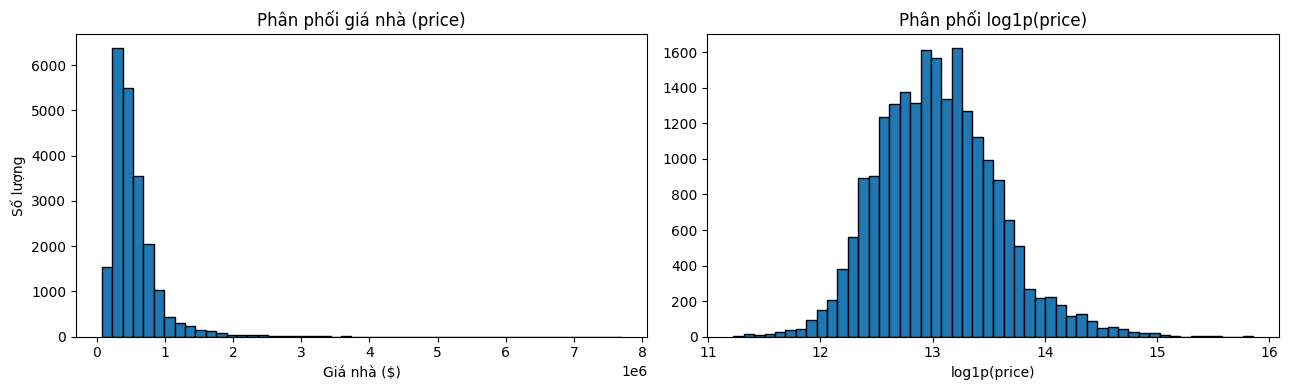

Các biến số tương quan mạnh nhất với price (Pearson):


,correlation_with_price
sqft_living,0.702040
grade,0.667444
sqft_above,0.605574
sqft_living15,0.585372
bathrooms,0.525168
view,0.397280
sqft_basement,0.323782
bedrooms,0.308330
lat,0.307012
waterfront,0.266367


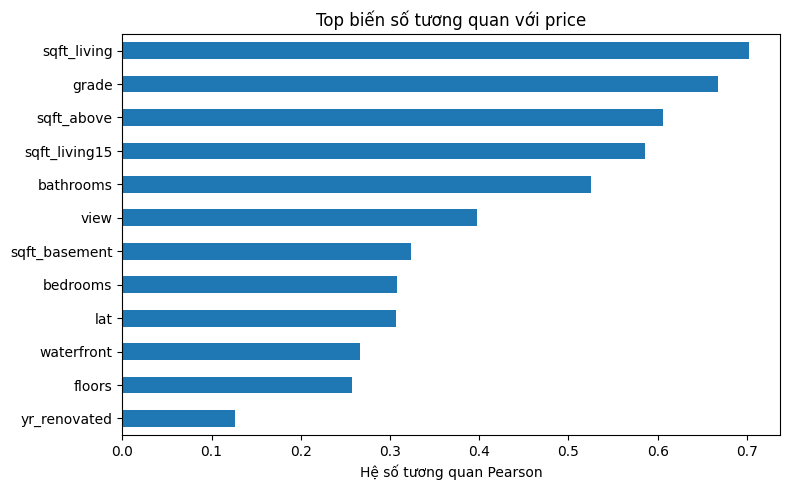

In [4]:
print("Kiểu dữ liệu và số lượng không thiếu:")
display(pd.DataFrame({
    "dtype": df_house.dtypes.astype(str),
    "non_null": df_house.notna().sum(),
    "missing": df_house.isna().sum(),
    "missing_%": (df_house.isna().mean() * 100).round(2)
}).sort_values("missing", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df_house["price"], bins=50, edgecolor="black")
axes[0].set_title("Phân phối giá nhà (price)")
axes[0].set_xlabel("Giá nhà ($)")
axes[0].set_ylabel("Số lượng")
axes[1].hist(np.log1p(df_house["price"]), bins=50, edgecolor="black")
axes[1].set_title("Phân phối log1p(price)")
axes[1].set_xlabel("log1p(price)")
plt.tight_layout()
plt.show()

numeric_for_corr = df_house.select_dtypes(include=np.number)
if "price" in numeric_for_corr.columns:
    corr_price = numeric_for_corr.corr(numeric_only=True)["price"].drop("price").sort_values(key=np.abs, ascending=False)
    print("Các biến số tương quan mạnh nhất với price (Pearson):")
    display(corr_price.head(12).to_frame("correlation_with_price"))
    corr_price.head(12).sort_values().plot(kind="barh", figsize=(8, 5), title="Top biến số tương quan với price")
    plt.xlabel("Hệ số tương quan Pearson")
    plt.tight_layout()
    plt.show()

## 4.3. Feature Engineering – tạo đặc trưng mới
Các đặc trưng tạo thêm gồm năm/tháng/ngày trong tuần bán nhà, tuổi nhà tại thời điểm bán, nhà đã cải tạo hay chưa, số năm kể từ lần cải tạo và một số tỷ lệ diện tích. Các trường `id` và `date` gốc sẽ không đưa trực tiếp vào mô hình.

In [5]:
def engineer_house_features(data: pd.DataFrame) -> pd.DataFrame:
    """Tạo feature mới một cách xác định; các phép chia không hợp lệ được đổi thành NaN."""
    out = data.copy()

    # Tách thông tin từ ngày giao dịch.
    if "date" in out.columns:
        sale_date = pd.to_datetime(
            out["date"].astype(str).str.replace(r"\.0$", "", regex=True),
            errors="coerce"
        )
        out["sale_year"] = sale_date.dt.year
        out["sale_month"] = sale_date.dt.month
        out["sale_dayofweek"] = sale_date.dt.dayofweek
    elif "yr_built" in out.columns:
        # Trường hợp file không có ngày giao dịch: dùng năm bán giả định thống nhất để tạo tuổi nhà.
        out["sale_year"] = int(pd.to_numeric(out["yr_built"], errors="coerce").max()) + 1

    # Tuổi nhà tại thời điểm bán.
    if "yr_built" in out.columns and "sale_year" in out.columns:
        out["house_age_at_sale"] = pd.to_numeric(out["sale_year"], errors="coerce") - pd.to_numeric(out["yr_built"], errors="coerce")
        out["house_age_at_sale"] = out["house_age_at_sale"].clip(lower=0)

    # Trạng thái và thời gian từ lần cải tạo gần nhất. yr_renovated = 0 nghĩa là chưa ghi nhận cải tạo.
    if "yr_renovated" in out.columns:
        renovated_year = pd.to_numeric(out["yr_renovated"], errors="coerce").fillna(0)
        out["is_renovated"] = (renovated_year > 0).astype(int)
        if "sale_year" in out.columns:
            sale_year = pd.to_numeric(out["sale_year"], errors="coerce")
            out["years_since_renovation"] = np.where(
                renovated_year > 0,
                (sale_year - renovated_year).clip(lower=0),
                0
            )

    # Tỷ lệ diện tích và diện tích trên mỗi phòng ngủ.
    if {"sqft_living", "sqft_lot"}.issubset(out.columns):
        out["living_lot_ratio"] = pd.to_numeric(out["sqft_living"], errors="coerce") / pd.to_numeric(out["sqft_lot"], errors="coerce").replace(0, np.nan)
    if {"sqft_living", "bedrooms"}.issubset(out.columns):
        out["sqft_per_bedroom"] = pd.to_numeric(out["sqft_living"], errors="coerce") / pd.to_numeric(out["bedrooms"], errors="coerce").replace(0, np.nan)
    if {"bathrooms", "bedrooms"}.issubset(out.columns):
        out["bathrooms_per_bedroom"] = pd.to_numeric(out["bathrooms"], errors="coerce") / pd.to_numeric(out["bedrooms"], errors="coerce").replace(0, np.nan)
    if {"sqft_basement", "sqft_living"}.issubset(out.columns):
        out["basement_living_ratio"] = pd.to_numeric(out["sqft_basement"], errors="coerce") / pd.to_numeric(out["sqft_living"], errors="coerce").replace(0, np.nan)
    if {"sqft_above", "sqft_living"}.issubset(out.columns):
        out["above_living_ratio"] = pd.to_numeric(out["sqft_above"], errors="coerce") / pd.to_numeric(out["sqft_living"], errors="coerce").replace(0, np.nan)

    # Chặn vô cực do chia và để pipeline xử lý NaN bằng imputer.
    out.replace([np.inf, -np.inf], np.nan, inplace=True)
    return out

# Bộ đặc trưng gốc để so sánh với bộ có Feature Engineering.
X_base = df_house.drop(columns=["price", "id", "date"], errors="ignore").copy()

df_house_fe = engineer_house_features(df_house)
X_fe = df_house_fe.drop(columns=["price", "id", "date"], errors="ignore").copy()
y_house = df_house["price"].astype(float).copy()

print("Số feature ban đầu:", X_base.shape[1])
print("Số feature sau Feature Engineering:", X_fe.shape[1])
print("Các feature mới được tạo:", [c for c in X_fe.columns if c not in X_base.columns])
display(X_fe.head())

Số feature ban đầu: 18
Số feature sau Feature Engineering: 29
Các feature mới được tạo: ['sale_year', 'sale_month', 'sale_dayofweek', 'house_age_at_sale', 'is_renovated', 'years_since_renovation', 'living_lot_ratio', 'sqft_per_bedroom', 'bathrooms_per_bedroom', 'basement_living_ratio', 'above_living_ratio']


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,sale_dayofweek,house_age_at_sale,is_renovated,years_since_renovation,living_lot_ratio,sqft_per_bedroom,bathrooms_per_bedroom,basement_living_ratio,above_living_ratio
0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650,2014,10,0,59,0,0,0.208850,393.333333,0.333333,0.000000,1.000000
1,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014,12,1,63,1,23,0.354874,856.666667,0.750000,0.155642,0.844358
2,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062,2015,2,2,82,0,0,0.077000,385.000000,0.500000,0.000000,1.000000
3,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000,2014,12,1,49,0,0,0.392000,490.000000,0.750000,0.464286,0.535714
4,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503,2015,2,2,28,0,0,0.207921,560.000000,0.666667,0.000000,1.000000


## 4.4. Chia train/test và xây dựng bộ tiền xử lý trong Pipeline
Dùng cùng một tập train/test (80/20) cho tất cả cấu hình. Mọi thao tác điền giá trị thiếu, chuẩn hóa, mã hóa và chọn feature đều nằm bên trong pipeline, chỉ được học từ tập train.

In [6]:
# Chia theo chỉ số để bộ gốc và bộ Feature Engineering dùng đúng cùng các mẫu.
idx_train, idx_test = train_test_split(
    np.arange(len(df_house)), test_size=0.20, random_state=42
)
y_train_house = y_house.iloc[idx_train]
y_test_house = y_house.iloc[idx_test]

X_base_train, X_base_test = X_base.iloc[idx_train].copy(), X_base.iloc[idx_test].copy()
X_fe_train, X_fe_test = X_fe.iloc[idx_train].copy(), X_fe.iloc[idx_test].copy()


def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    """Impute + scale numeric; impute + one-hot encode categorical (zipcode luôn là categorical)."""
    categorical_features = X.select_dtypes(include=["object", "category", "string", "bool"]).columns.tolist()
    if "zipcode" in X.columns and "zipcode" not in categorical_features:
        categorical_features.append("zipcode")
    numeric_features = [c for c in X.columns if c not in categorical_features]

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # tương thích các bản scikit-learn cũ
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ])

    transformers = []
    if numeric_features:
        transformers.append(("numeric", numeric_pipeline, numeric_features))
    if categorical_features:
        transformers.append(("categorical", categorical_pipeline, categorical_features))
    return ColumnTransformer(transformers=transformers, remainder="drop", verbose_feature_names_out=False)

print("Train:", X_fe_train.shape, "| Test:", X_fe_test.shape)
print("Tỷ lệ train/test: 80/20")

Train: (17287, 29) | Test: (4322, 29)
Tỷ lệ train/test: 80/20


## 4.5. So sánh nhiều thuật toán hồi quy
Các mô hình dùng cùng feature engineered và cùng tập test. Ngoài mô hình học trên `price` gốc, có thêm Ridge học trên `log1p(price)` để kiểm tra tác động của biến đổi mục tiêu khi phân phối giá lệch phải.

In [7]:
models_bai4 = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Lasso Regression": Lasso(alpha=500.0, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(max_depth=18, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=120, learning_rate=0.05, max_depth=2, random_state=42),
    "Hist. Gradient Boosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0, random_state=42),
    "Linear SVR": LinearSVR(C=1.0, max_iter=20000, dual=True, random_state=42),
}

results_bai4_models = []
fitted_models_bai4 = {}
predictions_bai4 = {}


def evaluate_predictions(y_true, y_pred):
    return {
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

for model_name, estimator in models_bai4.items():
    print("Đang huấn luyện:", model_name)
    pipe = Pipeline(steps=[
        ("preprocess", make_preprocessor(X_fe_train)),
        ("model", estimator)
    ])
    start_time = time.time()
    pipe.fit(X_fe_train, y_train_house)
    y_pred = pipe.predict(X_fe_test)
    elapsed = time.time() - start_time

    row = {"Mô hình": model_name, **evaluate_predictions(y_test_house, y_pred), "Thời gian (giây)": elapsed}
    results_bai4_models.append(row)
    fitted_models_bai4[model_name] = pipe
    predictions_bai4[model_name] = y_pred

# Thử biến đổi log mục tiêu; dự đoán được đổi ngược về đơn vị đô la để tính metric.
log_target_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocess", make_preprocessor(X_fe_train)),
        ("model", Ridge(alpha=10.0))
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
    check_inverse=False
)
print("Đang huấn luyện: Ridge Regression (log1p target)")
start_time = time.time()
log_target_model.fit(X_fe_train, y_train_house)
y_pred_log = log_target_model.predict(X_fe_test)
elapsed = time.time() - start_time
results_bai4_models.append({
    "Mô hình": "Ridge (log1p target)",
    **evaluate_predictions(y_test_house, y_pred_log),
    "Thời gian (giây)": elapsed
})
fitted_models_bai4["Ridge (log1p target)"] = log_target_model
predictions_bai4["Ridge (log1p target)"] = y_pred_log

results_bai4_models_df = pd.DataFrame(results_bai4_models).sort_values("RMSE ($)").reset_index(drop=True)
print("BẢNG SO SÁNH MÔ HÌNH – xếp theo RMSE tăng dần")
display(results_bai4_models_df.style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R²": "{:.4f}", "MAPE (%)": "{:.2f}%", "Thời gian (giây)": "{:.1f}"
}))

best_model_name_bai4 = results_bai4_models_df.iloc[0]["Mô hình"]
print(f"Mô hình tốt nhất theo RMSE trên tập test: {best_model_name_bai4}")

Đang huấn luyện: Linear Regression
Đang huấn luyện: Ridge Regression
Đang huấn luyện: Lasso Regression
Đang huấn luyện: Decision Tree
Đang huấn luyện: Random Forest
Đang huấn luyện: Extra Trees
Đang huấn luyện: Gradient Boosting
Đang huấn luyện: Hist. Gradient Boosting
Đang huấn luyện: Linear SVR
Đang huấn luyện: Ridge Regression (log1p target)
BẢNG SO SÁNH MÔ HÌNH – xếp theo RMSE tăng dần


,Mô hình,MAE ($),RMSE ($),R²,MAPE (%),Thời gian (giây)
0,Hist. Gradient Boosting,"$65,593","$118,617",0.9000,12.45%,2.3
1,Extra Trees,"$65,819","$122,334",0.8936,12.34%,12.6
2,Random Forest,"$68,983","$131,104",0.8779,12.85%,25.0
3,Ridge (log1p target),"$73,448","$131,601",0.8769,13.42%,0.2
4,Gradient Boosting,"$93,243","$157,550",0.8236,18.37%,7.2
5,Linear Regression,"$95,564","$165,745",0.8048,19.21%,0.2
6,Ridge Regression,"$95,869","$166,924",0.8020,19.27%,0.2
7,Lasso Regression,"$99,576","$171,421",0.7912,19.99%,1.0
8,Decision Tree,"$93,226","$177,640",0.7758,17.22%,0.9
9,Linear SVR,"$523,693","$644,187",-1.9490,95.70%,0.1


Mô hình tốt nhất theo RMSE trên tập test: Hist. Gradient Boosting


### Biểu đồ so sánh MAE, RMSE và R²

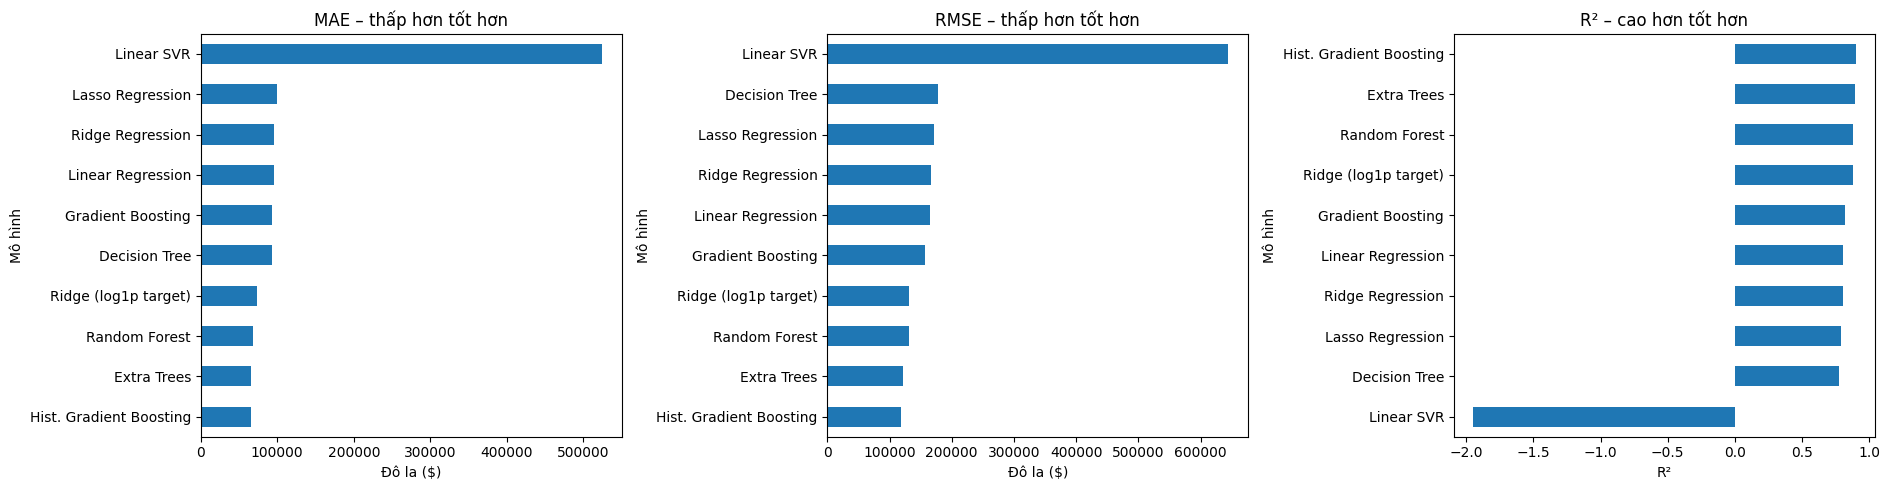

In [8]:
plot_df_bai4 = results_bai4_models_df.set_index("Mô hình")
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_df_bai4["MAE ($)"].sort_values().plot(kind="barh", ax=axes[0], title="MAE – thấp hơn tốt hơn")
plot_df_bai4["RMSE ($)"].sort_values().plot(kind="barh", ax=axes[1], title="RMSE – thấp hơn tốt hơn")
plot_df_bai4["R²"].sort_values().plot(kind="barh", ax=axes[2], title="R² – cao hơn tốt hơn")
axes[0].set_xlabel("Đô la ($)")
axes[1].set_xlabel("Đô la ($)")
axes[2].set_xlabel("R²")
plt.tight_layout()
plt.show()

## 4.6. Feature Selection – chọn đặc trưng và so sánh
So sánh Ridge trên feature gốc, Ridge trên feature đã tạo thêm, Ridge + `SelectKBest` (lọc theo F-test), và Ridge + `SelectFromModel` (chọn theo mức độ quan trọng của Extra Trees). Chọn đặc trưng nằm trong pipeline để tránh dùng thông tin của tập test.

In [9]:
# Cấu hình 1: Ridge với feature gốc – không thêm biến mới.
pipe_ridge_base = Pipeline(steps=[
    ("preprocess", make_preprocessor(X_base_train)),
    ("model", Ridge(alpha=10.0))
])
start_time = time.time()
pipe_ridge_base.fit(X_base_train, y_train_house)
pred_ridge_base = pipe_ridge_base.predict(X_base_test)
time_ridge_base = time.time() - start_time

# Cấu hình 2: Ridge + SelectKBest. k=20 đặc trưng sau mã hóa (nếu ít hơn thì tự giảm k).
preprocess_for_k = make_preprocessor(X_fe_train)
X_transformed_for_count = preprocess_for_k.fit_transform(X_fe_train)
k_features = min(20, X_transformed_for_count.shape[1])

pipe_ridge_kbest = Pipeline(steps=[
    ("preprocess", make_preprocessor(X_fe_train)),
    ("feature_selection", SelectKBest(score_func=f_regression, k=k_features)),
    ("model", Ridge(alpha=10.0))
])
start_time = time.time()
pipe_ridge_kbest.fit(X_fe_train, y_train_house)
pred_ridge_kbest = pipe_ridge_kbest.predict(X_fe_test)
time_ridge_kbest = time.time() - start_time

# Cấu hình 3: Wrapper selection bằng RFE (Recursive Feature Elimination).
n_rfe_features = min(20, X_transformed_for_count.shape[1])
pipe_ridge_rfe = Pipeline(steps=[
    ("preprocess", make_preprocessor(X_fe_train)),
    ("feature_selection", RFE(estimator=Ridge(alpha=10.0), n_features_to_select=n_rfe_features, step=0.25)),
    ("model", Ridge(alpha=10.0))
])
start_time = time.time()
pipe_ridge_rfe.fit(X_fe_train, y_train_house)
pred_ridge_rfe = pipe_ridge_rfe.predict(X_fe_test)
time_ridge_rfe = time.time() - start_time

# Cấu hình 4: chọn feature theo importance của Extra Trees rồi huấn luyện Ridge.
selector_extra_trees = ExtraTreesRegressor(
    n_estimators=50, max_depth=14, min_samples_leaf=3, random_state=42, n_jobs=-1
)
pipe_ridge_model_selection = Pipeline(steps=[
    ("preprocess", make_preprocessor(X_fe_train)),
    ("feature_selection", SelectFromModel(selector_extra_trees, threshold="median")),
    ("model", Ridge(alpha=10.0))
])
start_time = time.time()
pipe_ridge_model_selection.fit(X_fe_train, y_train_house)
pred_ridge_model_selection = pipe_ridge_model_selection.predict(X_fe_test)
time_ridge_model_selection = time.time() - start_time

# Lấy Ridge + toàn bộ feature engineered từ bảng kết quả mô hình để không huấn luyện lại.
ridge_fe_row = results_bai4_models_df.loc[results_bai4_models_df["Mô hình"] == "Ridge Regression"].iloc[0].to_dict()
selection_rows = [
    {"Cấu hình": "Ridge + feature gốc", **evaluate_predictions(y_test_house, pred_ridge_base), "Thời gian (giây)": time_ridge_base},
    {"Cấu hình": "Ridge + Feature Engineering", **evaluate_predictions(y_test_house, predictions_bai4["Ridge Regression"]), "Thời gian (giây)": float(ridge_fe_row["Thời gian (giây)"])},
    {"Cấu hình": f"Ridge + SelectKBest (k={k_features})", **evaluate_predictions(y_test_house, pred_ridge_kbest), "Thời gian (giây)": time_ridge_kbest},
    {"Cấu hình": f"Ridge + RFE (Top {n_rfe_features})", **evaluate_predictions(y_test_house, pred_ridge_rfe), "Thời gian (giây)": time_ridge_rfe},
    {"Cấu hình": "Ridge + SelectFromModel (Extra Trees)", **evaluate_predictions(y_test_house, pred_ridge_model_selection), "Thời gian (giây)": time_ridge_model_selection},
]
results_bai4_selection_df = pd.DataFrame(selection_rows).sort_values("RMSE ($)").reset_index(drop=True)
display(results_bai4_selection_df.style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R²": "{:.4f}", "MAPE (%)": "{:.2f}%", "Thời gian (giây)": "{:.1f}"
}))

,Cấu hình,MAE ($),RMSE ($),R²,MAPE (%),Thời gian (giây)
0,Ridge + Feature Engineering,"$95,869","$166,924",0.8020,19.27%,0.2
1,Ridge + feature gốc,"$98,014","$167,470",0.8007,20.02%,0.1
2,Ridge + SelectFromModel (Extra Trees),"$105,799","$176,422",0.7788,21.16%,4.3
3,Ridge + SelectKBest (k=20),"$120,075","$193,351",0.7343,23.59%,0.1
4,Ridge + RFE (Top 20),"$149,284","$227,444",0.6324,31.34%,0.2


### Các feature được giữ lại bởi từng phương pháp

In [11]:
# Tên feature sau imputation/scale/one-hot và mặt nạ feature selection.
feature_names_kbest = pipe_ridge_kbest.named_steps["preprocess"].get_feature_names_out()
mask_kbest = pipe_ridge_kbest.named_steps["feature_selection"].get_support()
selected_kbest = feature_names_kbest[mask_kbest]

feature_names_rfe = pipe_ridge_rfe.named_steps["preprocess"].get_feature_names_out()
mask_rfe = pipe_ridge_rfe.named_steps["feature_selection"].get_support()
selected_rfe = feature_names_rfe[mask_rfe]

feature_names_model = pipe_ridge_model_selection.named_steps["preprocess"].get_feature_names_out()
mask_model = pipe_ridge_model_selection.named_steps["feature_selection"].get_support()
selected_model = feature_names_model[mask_model]

print(f"SelectKBest giữ lại {len(selected_kbest)} feature:")
print(list(selected_kbest))
print(f"\nRFE giữ lại {len(selected_rfe)} feature:")
print(list(selected_rfe))
print("\nSelectFromModel (Extra Trees) giữ lại", len(selected_model), "feature:")
print(list(selected_model))

SelectKBest giữ lại 20 feature:
['bedrooms', 'bathrooms', 'sqft_living', 'floors', 'waterfront', 'view', 'grade', 'sqft_above', 'sqft_basement', 'lat', 'sqft_living15', 'sqft_per_bedroom', 'bathrooms_per_bedroom', 'basement_living_ratio', 'above_living_ratio', 'zipcode_98004', 'zipcode_98006', 'zipcode_98039', 'zipcode_98040', 'zipcode_98112']

RFE giữ lại 20 feature:
['sqft_living', 'zipcode_98004', 'zipcode_98011', 'zipcode_98014', 'zipcode_98019', 'zipcode_98022', 'zipcode_98028', 'zipcode_98039', 'zipcode_98040', 'zipcode_98072', 'zipcode_98077', 'zipcode_98102', 'zipcode_98105', 'zipcode_98109', 'zipcode_98112', 'zipcode_98119', 'zipcode_98122', 'zipcode_98133', 'zipcode_98155', 'zipcode_98199']

SelectFromModel (Extra Trees) giữ lại 49 feature:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 

## 4.7. Phân tích sai số và nhận xét tự động

,Giá thực tế ($),Giá dự đoán ($),Sai số tuyệt đối ($)
0,"$476,900","$463,376","$13,524"
1,"$235,000","$181,217","$53,783"
2,"$269,900","$297,474","$27,574"
3,"$400,000","$396,546","$3,454"
4,"$550,000","$600,672","$50,672"
5,"$347,000","$352,075","$5,075"
6,"$315,000","$363,611","$48,611"
7,"$597,400","$564,607","$32,793"
8,"$552,500","$529,065","$23,435"
9,"$302,000","$331,550","$29,550"


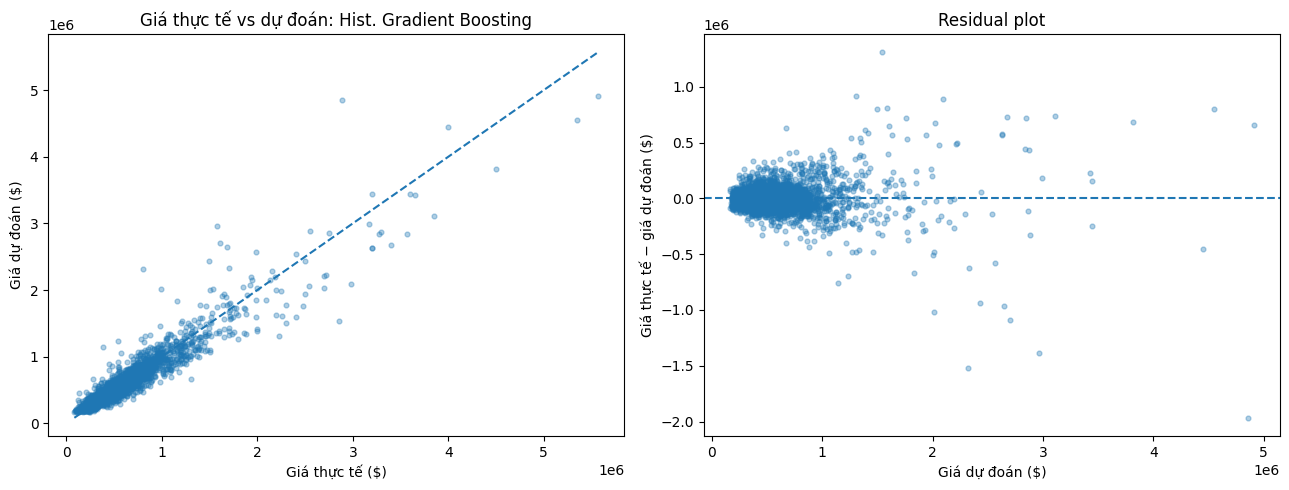

NHẬN XÉT TỰ ĐỘNG
- Theo RMSE, mô hình đứng đầu là: Hist. Gradient Boosting.
- MAE = $65,593; RMSE = $118,617; R² = 0.9000; MAPE = 12.45%.
- R² tương đối cao trên tập test: mô hình giải thích được phần lớn biến thiên giá, nhưng vẫn cần xem residual và ngoại lệ.
- Trong nhóm thử nghiệm Feature Engineering/Selection, cấu hình RMSE tốt nhất là: Ridge + Feature Engineering.
- MAE/RMSE càng thấp càng tốt; R² càng gần 1 càng tốt. MAPE là phần trăm sai số tuyệt đối trung bình và nhạy với các mẫu giá thấp.
- Kết quả chỉ có giá trị đánh giá tổng quát khi so sánh trên cùng tập test; chưa phải bằng chứng rằng mô hình sẽ tốt tương tự trên dữ liệu nhà ở ở thời kỳ/khu vực khác.


In [12]:
# So sánh giá thực tế và dự đoán cho mô hình có RMSE tốt nhất.
y_pred_best_bai4 = predictions_bai4[best_model_name_bai4]
compare_best_bai4 = pd.DataFrame({
    "Giá thực tế ($)": np.asarray(y_test_house),
    "Giá dự đoán ($)": np.asarray(y_pred_best_bai4),
})
compare_best_bai4["Sai số tuyệt đối ($)"] = np.abs(compare_best_bai4["Giá thực tế ($)"] - compare_best_bai4["Giá dự đoán ($)"])
display(compare_best_bai4.head(10).style.format("${:,.0f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test_house, y_pred_best_bai4, alpha=0.35, s=12)
min_val = min(float(np.min(y_test_house)), float(np.min(y_pred_best_bai4)))
max_val = max(float(np.max(y_test_house)), float(np.max(y_pred_best_bai4)))
axes[0].plot([min_val, max_val], [min_val, max_val], linestyle="--")
axes[0].set_title(f"Giá thực tế vs dự đoán: {best_model_name_bai4}")
axes[0].set_xlabel("Giá thực tế ($)")
axes[0].set_ylabel("Giá dự đoán ($)")
residuals_bai4 = np.asarray(y_test_house) - np.asarray(y_pred_best_bai4)
axes[1].scatter(y_pred_best_bai4, residuals_bai4, alpha=0.35, s=12)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residual plot")
axes[1].set_xlabel("Giá dự đoán ($)")
axes[1].set_ylabel("Giá thực tế − giá dự đoán ($)")
plt.tight_layout()
plt.show()

best_model_row_bai4 = results_bai4_models_df.iloc[0]
print("NHẬN XÉT TỰ ĐỘNG")
print(f"- Theo RMSE, mô hình đứng đầu là: {best_model_row_bai4['Mô hình']}.")
print(f"- MAE = ${best_model_row_bai4['MAE ($)']:,.0f}; RMSE = ${best_model_row_bai4['RMSE ($)']:,.0f}; R² = {best_model_row_bai4['R²']:.4f}; MAPE = {best_model_row_bai4['MAPE (%)']:.2f}%.")
if best_model_row_bai4["R²"] >= 0.75:
    print("- R² tương đối cao trên tập test: mô hình giải thích được phần lớn biến thiên giá, nhưng vẫn cần xem residual và ngoại lệ.")
elif best_model_row_bai4["R²"] >= 0.50:
    print("- R² ở mức trung bình-khá: đặc trưng nhà ở giúp dự đoán được một phần đáng kể biến thiên giá, nhưng còn sai số.")
else:
    print("- R² còn thấp: mô hình còn bỏ sót các yếu tố ảnh hưởng đến giá hoặc cần điều chỉnh đặc trưng/siêu tham số.")

best_selection_row = results_bai4_selection_df.iloc[0]
print(f"- Trong nhóm thử nghiệm Feature Engineering/Selection, cấu hình RMSE tốt nhất là: {best_selection_row['Cấu hình']}.")
print("- MAE/RMSE càng thấp càng tốt; R² càng gần 1 càng tốt. MAPE là phần trăm sai số tuyệt đối trung bình và nhạy với các mẫu giá thấp.")
print("- Kết quả chỉ có giá trị đánh giá tổng quát khi so sánh trên cùng tập test; chưa phải bằng chứng rằng mô hình sẽ tốt tương tự trên dữ liệu nhà ở ở thời kỳ/khu vực khác.")

## 4.8. Kết luận

Pipeline đã thực hiện các trường hợp chính của bài toán:
1. **Tiền xử lý:** điền giá trị thiếu, chuẩn hóa biến số, one-hot encode biến phân loại (đặc biệt `zipcode`).
2. **Feature Engineering:** khai thác ngày bán, tuổi nhà, trạng thái cải tạo, tỷ lệ diện tích và thử biến đổi log mục tiêu.
3. **Feature Selection:** `SelectKBest` (filter), `RFE` (wrapper) và `SelectFromModel` với Extra Trees (embedded/model-based).
4. **Mô hình:** Linear Regression, Ridge, Lasso, Decision Tree, Random Forest, Extra Trees, Gradient Boosting, HistGradientBoosting, Linear SVR và Ridge với mục tiêu `log1p(price)`.
5. **Đánh giá:** MAE, RMSE, R², MAPE và biểu đồ so sánh trên cùng một tập test.

**Khi viết báo cáo:** ghi số liệu trực tiếp từ hai bảng kết quả sau khi chạy notebook; không nên ghi trước một mô hình là tốt nhất vì thứ hạng phụ thuộc vào dữ liệu và phiên bản thư viện.